# Render Speed Analysis

These analyses were done on a 7800x3d.

## Multi-Threading

Benchmarks will be run on this image rendering:

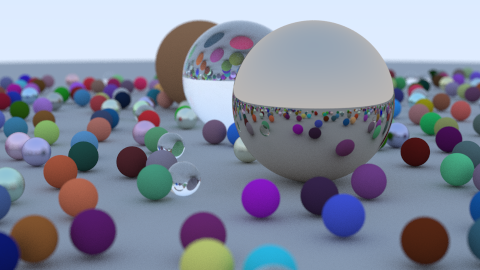

In [ ]:
import matplotlib.pyplot as plt
import subprocess, time

In [5]:
exe = r"..\src\build\Release\main.exe"  
image_width = 480
use_bvh = 0
thread_counts = [1, 2, 4, 8, 12, 16, 32, 64, 128]
times = [] 

for n in thread_counts:
    print(f"{n} threads")
    start = time.perf_counter()
    subprocess.run(
        [exe, str(image_width), str(n), str(use_bvh)],
        stdout=subprocess.DEVNULL, 
        stderr=subprocess.DEVNULL
    )
    end = time.perf_counter()
    times.append(end - start)
    print(f"{times[-1]:.2f} seconds")

1 threads
314.81 seconds
2 threads
181.42 seconds
4 threads
105.11 seconds
8 threads
62.44 seconds
12 threads
51.69 seconds
16 threads
53.43 seconds
32 threads
46.28 seconds
64 threads
43.79 seconds
128 threads
43.97 seconds


In [6]:
exe = r"..\src\build\Release\main.exe"  
image_width = 480
use_bvh = 1
thread_counts = [1, 2, 4, 8, 12, 16, 32, 64, 128]
bvh_times = [] 

for n in thread_counts:
    print(f"{n} threads")
    start = time.perf_counter()
    subprocess.run(
        [exe, str(image_width), str(n), str(use_bvh)],
        stdout=subprocess.DEVNULL, 
        stderr=subprocess.DEVNULL
    )
    end = time.perf_counter()
    bvh_times.append(end - start)
    print(f"{bvh_times[-1]:.2f} seconds")

1 threads
154.33 seconds
2 threads
113.84 seconds
4 threads
68.36 seconds
8 threads
41.47 seconds
12 threads
28.81 seconds
16 threads
26.93 seconds
32 threads
25.73 seconds
64 threads
23.45 seconds
128 threads
21.80 seconds


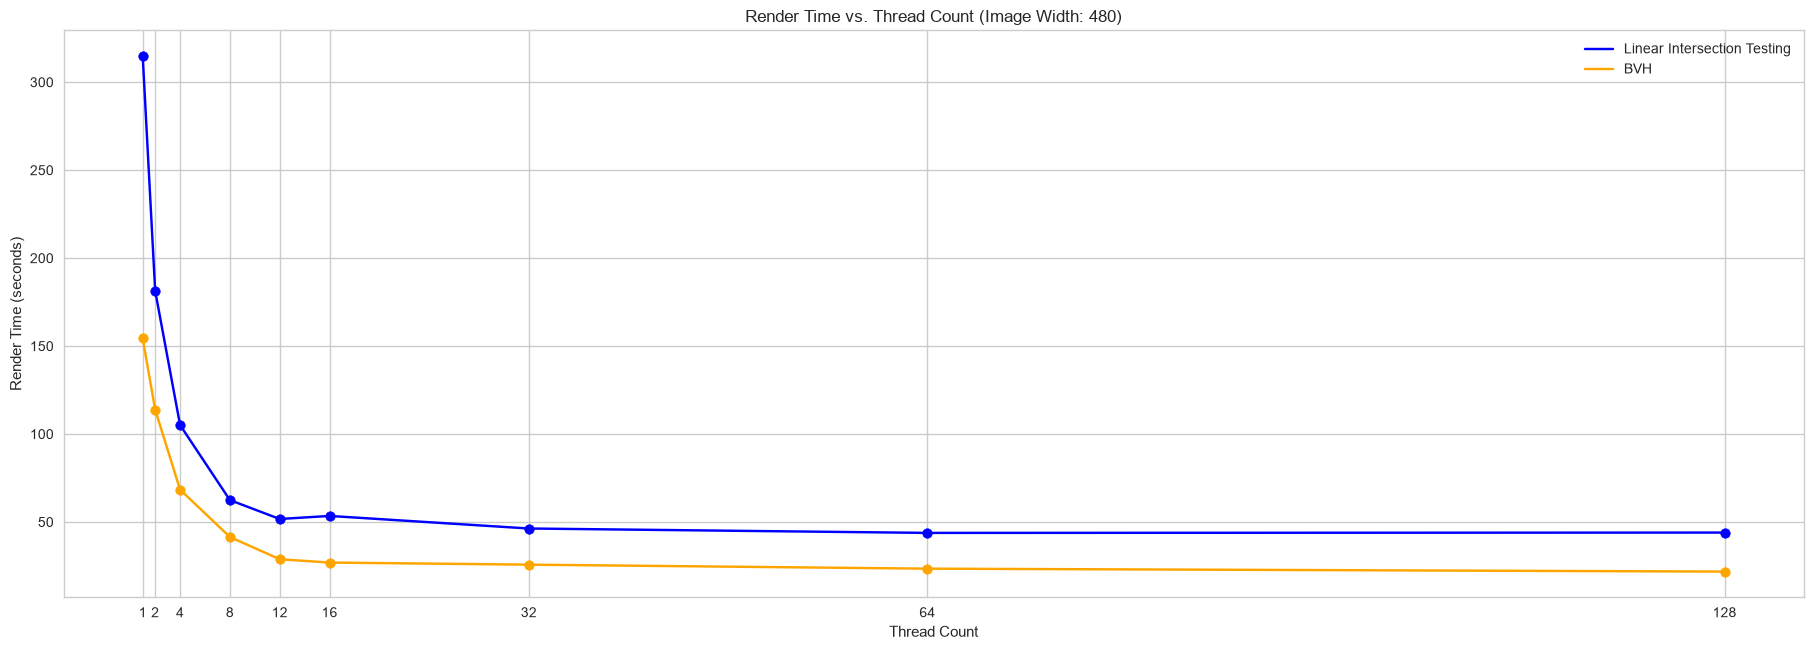

In [17]:
plt.figure(figsize=(20, 7))
plt.style.use('seaborn-v0_8-whitegrid')
plt.plot(thread_counts, times, color='blue', label='Linear Intersection Testing')
plt.scatter(thread_counts, times, color='blue')
plt.plot(thread_counts, bvh_times, color='orange', label='BVH')
plt.scatter(thread_counts, bvh_times, color='orange')
plt.xticks(thread_counts)
plt.xlabel("Thread Count")
plt.ylabel("Render Time (seconds)")
plt.title(f"Render Time vs. Thread Count (Image Width: {image_width})")
plt.legend()


In [26]:
times[0]/times[5], bvh_times[0]/bvh_times[5]

(5.892196352292387, 5.730600305040352)

In [27]:
times[0]/bvh_times[0], times[5]/bvh_times[5]

(2.0398331012626523, 1.9838897914152709)